<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/Fig2_J_K_markers_of_PCP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# This Google Colab notebook contains our analysis on multimodal (across transcriptomics and proteomics) markers of PCP compared to ACP.

### Mounting Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Load proteomics hits from one method - PCP vs ACP - Kim et al.

In [ ]:
!pip install openpyxl
!pip install statsmodels
!pip install scanpy
!pip install biomart
!pip install matplotlib_venn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 190.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 25.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 197.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376

In [ ]:
import pandas as pd
proteomics_results = pd.read_excel("/content/drive/MyDrive/pituitary_tumor_atlas/pcp/kim_proteomics_acp_pcp_supp_table.xlsx",header=5)
all_prot_genes_1 = proteomics_results["Gene names"].values
#keep where 'q-value' <0.05 and ACP_PCP == PCP_UP
proteomics_results = proteomics_results[(proteomics_results['q-value'] < 0.1) & (proteomics_results['Difference ACP_PCP'] < 0)]
proteomics_results_up1 = proteomics_results["Gene names"].values
proteomics_results_up1[:5]

<ArrowStringArray>
['TMEM120A', 'PECAM1', 'COL1A2', 'GPX1', 'IKBKG']
Length: 5, dtype: str

#Load proteomics hits from other method - PCP vs ACP - Kim et al.

In [ ]:
#load /content/drive/MyDrive/pituitary_tumor_atlas/pcp/kim_proteomics_acp_pcp_supp_table.xlsx
proteomics_results = pd.read_excel("/content/drive/MyDrive/pituitary_tumor_atlas/pcp/kim_proteomics_acp_pcp_supp_table_2.xlsx",header=5)
#keep where 'q-value' <0.05 and ACP_PCP == PCP_UP
all_prot_genes_2 = proteomics_results["Gene Name"].values
proteomics_results = proteomics_results[(proteomics_results['q-value'] < 0.1) & (proteomics_results['Difference ACP_PCP'] < 0)]
proteomics_results_up2 = proteomics_results["Gene Name"].values
proteomics_results_up2[:5]

<ArrowStringArray>
['SFXN1', 'MPP7', 'NSUN4', 'NIPSNAP3A', 'DHCR24']
Length: 5, dtype: str

#Load rna-seq results - PCP vs ACP - Apps et al.


In [ ]:
#load /content/drive/MyDrive/pituitary_tumor_atlas/pcp/apps_2024_rnaseq_supp_table.xlsx
rna_seq_results = pd.read_excel("/content/drive/MyDrive/pituitary_tumor_atlas/pcp/apps_2024_rnaseq_supp_table.xlsx",sheet_name="a) DE PCP vs ACP")


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
#remove whre lfcSE nan
rna_seq_results = rna_seq_results[~rna_seq_results['lfcSE'].isna()]
#remove where log2FoldChange is nan
rna_seq_results = rna_seq_results[~rna_seq_results['log2FoldChange'].isna()]
#Calculate the test statistic
rna_seq_results['stat'] = rna_seq_results['log2FoldChange'] / rna_seq_results['lfcSE']

#remove where stat is nan
rna_seq_results = rna_seq_results[~rna_seq_results['stat'].isna()]

In [ ]:
# Calculate p-values from the test statistic
rna_seq_results['pvalue2'] = 2 * (1 - norm.cdf(np.abs(rna_seq_results['stat'])))

# Adjust p-values for multiple testing using Benjamini-Hochberg (FDR)
rna_seq_results['padj2'] = multipletests(rna_seq_results['pvalue2'], method='fdr_bh')[1]

# Now 'rna_seq_results' contains the additional columns 'stat', 'pvalue', and 'padj'
print(rna_seq_results)

              ENSBL ID    baseMean  log2FoldChange     lfcSE      stat  \
0      ENSG00000143554   13.527384       24.242349  3.374771  7.183406   
1      ENSG00000123584   11.253475       23.988896  3.375102  7.107607   
2      ENSG00000256861    7.121780       23.342700  3.376252  6.913791   
3      ENSG00000273217    4.411722       22.674088  3.080125  7.361419   
4      ENSG00000145113  181.161247        7.801187  3.339945  2.335723   
...                ...         ...             ...       ...       ...   
24321  ENSG00000250111   37.567843       -7.838819  2.295285 -3.415184   
24322  ENSG00000275385   61.851109       -8.557634  1.870890 -4.574097   
24323  ENSG00000257093    3.969314      -19.909061  3.459108 -5.755548   
24324  ENSG00000116521   36.830364      -22.897253  3.000004 -7.632406   
24325  ENSG00000234287   40.531269      -23.038233  2.900276 -7.943461   

             pvalue          padj        SYMBOL       pvalue2         padj2  
0               NaN           NaN

In [ ]:
import pandas as pd

# Current Ensembl human GTF, release 116
url = (
    "https://ftp.ensembl.org/pub/release-116/gtf/homo_sapiens/"
    "Homo_sapiens.GRCh38.116.gtf.gz"
)

df = pd.read_csv(
    url,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chromosome",
        "source",
        "feature",
        "start",
        "end",
        "score",
        "strand",
        "frame",
        "attributes"
    ]
)

# Keep transcript records
tx = df[df["feature"] == "transcript"].copy()

# Extract attributes
tx["Transcript ID"] = tx["attributes"].str.extract(
    r'transcript_id "([^"]+)"'
)

tx["Gene ID"] = tx["attributes"].str.extract(
    r'gene_id "([^"]+)"'
)

tx["Gene Symbol"] = tx["attributes"].str.extract(
    r'gene_name "([^"]+)"'
)

mapping = tx[
    ["Transcript ID", "Gene ID", "Gene Symbol"]
].drop_duplicates()

print(mapping.head())


/tmp/ipykernel_940/326705319.py:9: DtypeWarning: Columns (0: chromosome) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


      Transcript ID          Gene ID Gene Symbol
1   ENST00000641871  ENSG00000284616         NaN
7   ENST00000564261  ENSG00000260972         NaN
10  ENST00000449232  ENSG00000229280     EEF1DP6
13  ENST00000634256  ENSG00000232596   LINC01646
16  ENST00000635556  ENSG00000232596   LINC01646


In [ ]:
rna_seq_results['gene_symbol'] = rna_seq_results['SYMBOL']
all_rna_genes = rna_seq_results['gene_symbol'] .values
#keep gene_symbol where log2FoldChange > 0 and padj2 < 0.05
rna_seq_results_up = rna_seq_results[(rna_seq_results['log2FoldChange'] > 0) & (rna_seq_results['padj2'] < 0.05)]
rna_seq_results_up_genes = rna_seq_results_up['gene_symbol'].unique()
#remove nan
rna_seq_results_up_genes = [x for x in rna_seq_results_up_genes if str(x) != 'nan']
len(rna_seq_results_up_genes)

1638

#Load genes that are sc/epithelial markers in the integrated object

In [ ]:
markers=pd.read_csv("/content/drive/MyDrive/human_pcp/supplement/Supplementary_Table_1.csv")

sc_markers = markers[markers['Cluster'].str.contains('Stem.like')]
epi_markers = markers[markers['Cluster'].str.contains('Epithelial')]
epi_markers_genes = epi_markers['Gene'].values
sc_markers_genes = sc_markers['Gene'].values

In [ ]:
sc_vs_epi = pd.read_csv("/content/drive/MyDrive/human_pcp/supplement/Supplementary_Table_2.csv")
#keep where under adj.P.Val < 0.1
sc_vs_epi = sc_vs_epi[sc_vs_epi['adj.P.Val'] < 0.1]
epi_genes = sc_vs_epi[sc_vs_epi['logFC'] < 0]['genes'].values
sc_genes = sc_vs_epi[sc_vs_epi['logFC'] > 0]['genes'].values


In [ ]:
#find MUC1
sc_vs_epi[sc_vs_epi['genes'].str.contains('PSCA')]

,logFC,AveExpr,t,P.Value,adj.P.Val,B,genes
700,-1.609218,1.166696,-3.047179,0.003141,0.050749,-2.265032,PSCA


# Make Venn diagram

In [ ]:
# Convert to numpy array and then to sets
rna_seq_results_up_genes = np.array(rna_seq_results_up_genes)
proteomics_results_up1 = set(proteomics_results_up1)
proteomics_results_up2 = set(proteomics_results_up2)
rna_seq_results_up_genes = set(rna_seq_results_up_genes)

/usr/local/lib/python3.13/dist-packages/matplotlib_venn/_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


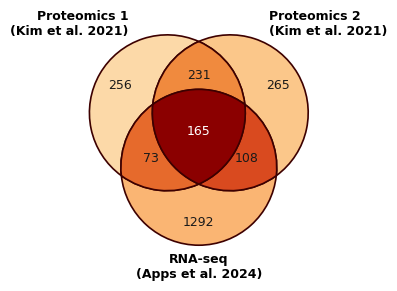

In [ ]:
from matplotlib_venn import venn3_unweighted
import matplotlib.pyplot as plt

# Nature-style plotting parameters
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 9
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

fig1, ax1 = plt.subplots(figsize=(4, 3))

v = venn3_unweighted(
    [proteomics_results_up1, proteomics_results_up2, rna_seq_results_up_genes],
    set_labels=('Proteomics 1\n(Kim et al. 2021)',
                'Proteomics 2\n(Kim et al. 2021)',
                'RNA-seq\n(Apps et al. 2024)'),
)

# Gradient from warm amber (singletons) → orange (pairwise) → deep crimson (center)
region_colors = {
    # Singletons — lightest, warm amber/orange
    '100': '#FCD9A8',  # only set A
    '010': '#FBC78A',  # only set B
    '001': '#FAB573',  # only set C
    # Pairwise intersections — mid orange/red
    '110': '#F08A3E',  # A ∩ B
    '101': '#E66A2C',  # A ∩ C
    '011': '#D94A1F',  # B ∩ C
    # Triple intersection — deepest crimson
    '111': '#8B0000',
}

for region_id, color in region_colors.items():
    patch = v.get_patch_by_id(region_id)
    if patch is not None:
        patch.set_color(color)
        patch.set_alpha(1.0)            # solid fills so the gradient reads cleanly
        patch.set_edgecolor('#3D0000')
        patch.set_linewidth(1.2)

# Set labels
for label in v.set_labels:
    if label is not None:
        label.set_fontsize(9)
        label.set_fontweight('bold')

# Subset numbers — white on the dark center for legibility
for region_id in ('100', '010', '001', '110', '101', '011', '111'):
    lbl = v.get_label_by_id(region_id)
    if lbl is not None:
        lbl.set_fontsize(9)
        lbl.set_color('white' if region_id == '111' else '#1a1a1a')

plt.title('')
plt.tight_layout()

plt.savefig('/content/drive/MyDrive/human_pcp/venn.png', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig('/content/drive/MyDrive/human_pcp/venn.svg', dpi=600, bbox_inches='tight', transparent=True)
plt.show()


In [ ]:
intersection = set(proteomics_results_up1).intersection(set(proteomics_results_up2)).intersection(set(rna_seq_results_up_genes))
print(len(intersection))
#save as csv
intersection_table = pd.DataFrame(intersection, columns=['Gene'])
intersection_table.to_csv("/content/drive/MyDrive/human_pcp/supplement/Supplementary_Table_8.csv")
background = set(all_prot_genes_1).intersection(set(all_prot_genes_2)).intersection(set(all_rna_genes))
print(len(background))
#write to csv
background_table = pd.DataFrame(background, columns=['Gene'])
background_table.to_csv("/content/drive/MyDrive/human_pcp/supplement/background_multimodal.csv")
intersection

165
519


{'ACADVL',
 'ACO2',
 'ACOT11',
 'ADCK5',
 'AFG3L2',
 'AGTRAP',
 'AHNAK2',
 'AKR1B10',
 'ALDH4A1',
 'ALOX15B',
 'ANXA1',
 'ANXA2',
 'APPL2',
 'ARPC1B',
 'ARPC2',
 'ARPC4',
 'ARPC5L',
 'ASS1',
 'ATAD3A',
 'BAG1',
 'BAIAP2',
 'BAK1',
 'BASP1',
 'C1QBP',
 'CALML3',
 'CD177',
 'CD46',
 'CD58',
 'CERS3',
 'CHP1',
 'CIB1',
 'CLCA2',
 'CLCA4',
 'CLEC2B',
 'CLTB',
 'COMTD1',
 'CORO2A',
 'CPT2',
 'CRAT',
 'CSTB',
 'CTSC',
 'CTTN',
 'CYB5R1',
 'CYC1',
 'DBNL',
 'DHCR24',
 'DHRS1',
 'DNAJC11',
 'DPYD',
 'ECI1',
 'ECM1',
 'EFHD2',
 'EPHA2',
 'EPS8L2',
 'ERLIN1',
 'ETHE1',
 'EVPL',
 'FABP5',
 'FAM129B',
 'FAM20C',
 'FAM83B',
 'FAM83H',
 'FLOT2',
 'FNDC3B',
 'GALNT2',
 'GALNT5',
 'GCLC',
 'GGT1',
 'GIPC1',
 'GPX1',
 'GSR',
 'GSTK1',
 'HK1',
 'HSD17B10',
 'HSPH1',
 'IL1RN',
 'ISOC2',
 'KRT13',
 'LAD1',
 'LETM1',
 'LRRC8E',
 'LYPD3',
 'MFF',
 'MFSD5',
 'MGST2',
 'MME',
 'MRC2',
 'MRPS34',
 'MTX1',
 'NAPRT',
 'NDUFS8',
 'NFKB1',
 'NSFL1C',
 'OGDH',
 'P4HB',
 'PC',
 'PIEZO1',
 'PKP3',
 'PLBD1',
 'PLIN3',

# how many of these are sc markers?

In [ ]:
sc_epi_markers = pd.read_csv(
    "/content/drive/MyDrive/human_pcp/supplement/Supplementary_Table_1.csv"
)

sc_epi_markers = sc_epi_markers[
    sc_epi_markers["Cluster"].str.contains("Stem.like|Epithelial", na=False)
]
sc_epi_markers = sc_epi_markers[sc_epi_markers["Gene"].isin(intersection)]
sc_epi_markers_in_intersection = sc_epi_markers[sc_epi_markers["Gene"].isin(intersection)]
#how many of gene are in intersection
intersection_in_markers = set(intersection).intersection(set(sc_epi_markers["Gene"]))
#how many are not in intersection
intersection_not_in_markers = set(intersection).difference(set(sc_epi_markers_in_intersection["Gene"]))
print(len(intersection_in_markers))
print(len(intersection_not_in_markers))



87
78


In [ ]:
sc_epi_markers_in_intersection["Cluster"].value_counts()

Cluster
Epithelial.cells    79
Stem.like.cells     79
Name: count, dtype: int64

In [ ]:
#difference in epi vs stem markers
epi_intersection = sc_epi_markers_in_intersection[sc_epi_markers_in_intersection["Cluster"].str.contains("Epithelial", na=False)]
stem_intersection = sc_epi_markers_in_intersection[sc_epi_markers_in_intersection["Cluster"].str.contains("Stem.like", na=False)]
difference = set(epi_intersection["Gene"]).difference(set(stem_intersection["Gene"]))
print(len(difference))
difference

8


{'CORO2A', 'CYB5R1', 'GSTK1', 'MRPS34', 'P4HB', 'S100A8', 'S100A9', 'VAMP8'}

In any marker set: 103
Not a marker: 62


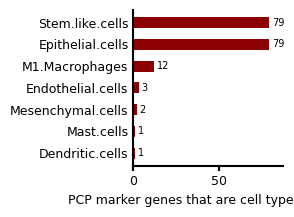

In any marker set: 103
Not a marker: 62


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "Arial", "font.size": 9, "svg.fonttype": "none"})

all_markers = pd.read_csv(
    "/content/drive/MyDrive/human_pcp/supplement/Supplementary_Table_1.csv"
)

intersection_set = set(intersection)
hits = all_markers[all_markers["Gene"].isin(intersection_set)]

counts = (
    hits.drop_duplicates(["Cluster", "Gene"])
        .groupby("Cluster")["Gene"]
        .nunique()
        .sort_values()
)

print("In any marker set:", len(intersection_set & set(all_markers["Gene"])))
print("Not a marker:", len(intersection_set - set(all_markers["Gene"])))

fig, ax = plt.subplots(figsize=(3, 0.22 * len(counts) + 0.7))
ax.barh(counts.index, counts.values, color="#8b0000", height=0.5)
ax.bar_label(ax.containers[0], padding=2, fontsize=7)

ax.set_xlabel("PCP marker genes that are cell type markers")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.margins(x=0.1)

plt.tight_layout()
plt.savefig("intersection_markers_barplot.svg", bbox_inches="tight")
plt.show()

print("In any marker set:", len(intersection_set & set(all_markers["Gene"])))
print("Not a marker:", len(intersection_set - set(all_markers["Gene"])))

Order consensus markers

In [ ]:
markers_df = pd.read_csv("/content/drive/MyDrive/human_pcp/all_results_sig.csv")
#find KLF5
markers_df = markers_df[markers_df['genes'].str.contains('KLF5')]
markers_df = markers_df.sort_values(by='logFC', ascending=False)
markers_df

,Unnamed: 0,logFC,AveExpr,t,P.Value,adj.P.Val,B,genes,comparison
319187,Epithelial.cells_vs_CD4.T.regs.KLF5,6.776786,4.757941,5.025732,3.059365e-06,1.937541e-05,4.370682,KLF5,Epithelial.cells_vs_CD4.T.regs
881725,Stem.like.cells_vs_CD4.T.regs.KLF5,6.662941,4.757941,4.982684,3.624479e-06,1.940706e-05,4.166242,KLF5,Stem.like.cells_vs_CD4.T.regs
372854,Epithelial.cells_vs_Neutrophils.KLF5,5.945609,4.757941,4.097283,1.005342e-04,6.417199e-04,1.140936,KLF5,Epithelial.cells_vs_Neutrophils
366207,Epithelial.cells_vs_Naive.B.cells.KLF5,5.942413,4.757941,5.923611,7.805319e-08,5.171850e-07,7.764993,KLF5,Epithelial.cells_vs_Naive.B.cells
937998,Stem.like.cells_vs_Neutrophils.KLF5,5.831764,4.757941,4.047839,1.197968e-04,6.307146e-04,0.911446,KLF5,Stem.like.cells_vs_Neutrophils
...,...,...,...,...,...,...,...,...,...
743463,Neutrophils_vs_Stem.like.cells.KLF5,-5.831764,4.757941,-4.047839,1.197968e-04,6.307146e-04,0.911446,KLF5,Neutrophils_vs_Stem.like.cells
660438,Naive.B.cells_vs_Epithelial.cells.KLF5,-5.942413,4.757941,-5.923611,7.805319e-08,5.171850e-07,7.764993,KLF5,Naive.B.cells_vs_Epithelial.cells
716408,Neutrophils_vs_Epithelial.cells.KLF5,-5.945609,4.757941,-4.097283,1.005342e-04,6.417199e-04,1.140936,KLF5,Neutrophils_vs_Epithelial.cells
110498,CD4.T.regs_vs_Stem.like.cells.KLF5,-6.662941,4.757941,-4.982684,3.624479e-06,1.940706e-05,4.166242,KLF5,CD4.T.regs_vs_Stem.like.cells


In [ ]:
len(intersection)

165

In [ ]:
markers_df = pd.read_csv("/content/drive/MyDrive/human_pcp/all_results_sig.csv")

# keep only Stem.* or Epi* comparisons
markers_df = markers_df[markers_df['comparison'].str.startswith(('Stem.', 'Epi'))]

# average logFC per gene
markers_df = markers_df.groupby('genes', as_index=False)['logFC'].mean()

markers_df = markers_df.sort_values(by='logFC', ascending=False)
#keep those in  intersection
markers_df_intersection = markers_df[markers_df['genes'].isin(intersection)]
markers_df_intersection  = markers_df_intersection .sort_values(by='logFC', ascending=False)
markers_df_intersection

,genes,logFC
8310,S100A2,9.489194
8314,S100A9,8.892179
8569,SFN,7.776646
8313,S100A8,7.380599
9909,TMPRSS11E,7.357028
...,...,...
2517,DPYD,-0.646284
9332,STX4,-0.715150
10524,VASP,-0.784180
626,ARPC4,-0.867018


In [ ]:
markers_df_all = pd.read_csv("/content/drive/MyDrive/human_pcp/all_results_sig.csv")

# keep only Stem.* or Epi* comparisons
markers_df_all = markers_df_all[markers_df_all['comparison'].str.startswith(('Stem.', 'Epi'))]
markers_df_all = markers_df_all .groupby('genes', as_index=False)['logFC'].mean()
#keep where mean above >0
markers_df_all = markers_df_all[markers_df_all['logFC'] > 0]
markers_df_all

,genes,logFC
1,A2ML1,5.505782
2,A2ML1-AS1,3.237285
3,A4GALT,4.608228
4,AACS,1.107361
5,AAGAB,0.402911
...,...,...
11111,ZNRF1,1.132866
11113,ZNRF3,1.723528
11114,ZPR1,0.556723
11125,ZSWIM8,0.650232


# Overall TFs that are up in PCP both according to Bulk RNA-seq comparing it to ACP, and also according to single-cell comparing to the other cell types

Load list of TFs from https://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt

In [ ]:
#https://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt
tfs2 = pd.read_csv("https://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt",header=None)
tfs2 = tfs2[0].values
tfs2

<ArrowStringArray>
['AC008770.3', 'AC023509.3', 'AC092835.1', 'AC138696.1',       'ADNP',
      'ADNP2',      'AEBP1',      'AEBP2',     'AHCTF1',      'AHDC1',
 ...
     'ZSCAN4',    'ZSCAN5A',    'ZSCAN5B',    'ZSCAN5C',     'ZSCAN9',
      'ZUFSP',       'ZXDA',       'ZXDB',       'ZXDC',       'ZZZ3']
Length: 1639, dtype: str

In [ ]:
#find genes that are TFs (tfs2), in rna_seq_results padj2 is <0.05 and also in markers_df
genes = list(set(rna_seq_results_up_genes).intersection(set(markers_df_all['genes'])))
genes = list(set(genes).intersection(set(tfs2)))
rna_seq_results_tfs = rna_seq_results[rna_seq_results['gene_symbol'].isin(genes)]
#sort by padj2
rna_seq_results_tfs = rna_seq_results_tfs.sort_values(by='padj2')
rna_seq_results_tfs

,ENSBL ID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,SYMBOL,pvalue2,padj2,gene_symbol
205,ENSG00000169594,742.450524,3.856671,0.454476,8.485977,2.139139e-17,7.867913e-15,BNC1,0.000000e+00,0.000000e+00,BNC1
192,ENSG00000175592,173.364579,3.900405,0.484530,8.049870,8.288174e-16,2.253935e-13,FOSL1,8.881784e-16,2.729294e-13,FOSL1
454,ENSG00000069812,1006.336159,2.977229,0.382997,7.773513,7.633864e-15,1.688174e-12,HES2,7.549517e-15,1.970667e-12,HES2
489,ENSG00000163435,484.457439,2.906383,0.374713,7.756285,8.745324e-15,1.900190e-12,ELF3,8.659740e-15,2.236424e-12,ELF3
397,ENSG00000172818,215.154459,3.135214,0.433067,7.239562,4.501377e-13,7.305299e-11,OVOL1,4.500844e-13,8.536132e-11,OVOL1
1041,ENSG00000112561,359.873348,2.023133,0.332325,6.087823,1.144566e-09,8.406296e-08,TFEB,1.144566e-09,9.853010e-08,TFEB
1457,ENSG00000172216,651.304002,1.663146,0.278278,5.976563,2.278938e-09,1.513576e-07,CEBPB,2.278938e-09,1.778891e-07,CEBPB
1026,ENSG00000160685,888.779373,2.030316,0.340699,5.959264,2.533771e-09,1.655506e-07,ZBTB7B,2.533771e-09,1.946513e-07,ZBTB7B
576,ENSG00000173153,342.607654,2.709684,0.456024,5.941976,2.816072e-09,1.804797e-07,ESRRA,2.816072e-09,2.123074e-07,ESRRA
1486,ENSG00000129911,255.634865,1.637715,0.278332,5.884042,4.003667e-09,2.412270e-07,KLF16,4.003667e-09,2.841901e-07,KLF16


In [ ]:
rna_seq_results_tfs["gene_symbol"].values

array(['BNC1', 'FOSL1', 'HES2', 'ELF3', 'OVOL1', 'TFEB', 'CEBPB',
       'ZBTB7B', 'ESRRA', 'KLF16', 'RARG', 'IRF6', 'VDR', 'ZBTB7A',
       'ZBTB7C', 'KLF5', 'ZNF385A', 'BHLHE40', 'MYC', 'MAFF', 'ELF4',
       'NFE2L1', 'BHLHE41', 'HMGA1', 'PRDM1', 'ARNTL2', 'NR1D1', 'SREBF1',
       'GRHL1', 'MNT', 'IRF2', 'NR2F6', 'ZNF524', 'DBP', 'CREB3L2',
       'NPAS2', 'MXD1', 'CEBPD', 'TRERF1', 'FOXC2', 'HES1', 'MECOM',
       'ELK1', 'IKZF2', 'IRX3', 'ZNF598', 'GATA3', 'ZNF750', 'KLF13',
       'ZNF467', 'RREB1'], dtype=object)

/usr/local/lib/python3.13/dist-packages/matplotlib_venn/_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


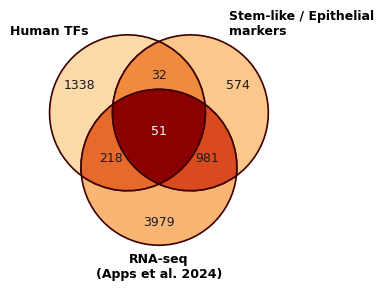

In [ ]:
from matplotlib_venn import venn3_unweighted
import matplotlib.pyplot as plt

# Nature-style plotting parameters
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 9
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

fig1, ax1 = plt.subplots(figsize=(4, 3))

v = venn3_unweighted(
    [set(tfs2), set(rna_seq_results_up_genes), set(markers_df_all['genes'])],

    set_labels=('Human TFs',
                'Stem-like / Epithelial \nmarkers',
                'RNA-seq\n(Apps et al. 2024)'),
)

# Gradient from warm amber (singletons) → orange (pairwise) → deep crimson (center)
region_colors = {
    # Singletons — lightest, warm amber/orange
    '100': '#FCD9A8',  # only set A
    '010': '#FBC78A',  # only set B
    '001': '#FAB573',  # only set C
    # Pairwise intersections — mid orange/red
    '110': '#F08A3E',  # A ∩ B
    '101': '#E66A2C',  # A ∩ C
    '011': '#D94A1F',  # B ∩ C
    # Triple intersection — deepest crimson
    '111': '#8B0000',
}

for region_id, color in region_colors.items():
    patch = v.get_patch_by_id(region_id)
    if patch is not None:
        patch.set_color(color)
        patch.set_alpha(1.0)            # solid fills so the gradient reads cleanly
        patch.set_edgecolor('#3D0000')
        patch.set_linewidth(1.2)

# Set labels
for label in v.set_labels:
    if label is not None:
        label.set_fontsize(9)
        label.set_fontweight('bold')

# Subset numbers — white on the dark center for legibility
for region_id in ('100', '010', '001', '110', '101', '011', '111'):
    lbl = v.get_label_by_id(region_id)
    if lbl is not None:
        lbl.set_fontsize(9)
        lbl.set_color('white' if region_id == '111' else '#1a1a1a')

plt.title('')
plt.tight_layout()

plt.savefig('/content/drive/MyDrive/human_pcp/venn2.png', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig('/content/drive/MyDrive/human_pcp/venn2.svg', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
#how much of this intersects with sc_markers
intersection= set(rna_seq_results_tfs["gene_symbol"])
print(len(intersection.intersection(set(sc_markers_genes)))) #higher in sc
#how much epi
print(len(intersection.intersection(set(epi_markers_genes)))) # higher in epi


19
17


# Load list of cell surface markers from https://v16.proteinatlas.org/about/download

In [ ]:
#/content/drive/MyDrive/pituitary_tumor_atlas/pcp/subcellular_location.csv
membrane_proteins = pd.read_csv("/content/drive/MyDrive/pituitary_tumor_atlas/pcp/subcellular_location.csv")
mask = membrane_proteins['Validated'].str.contains("Plasma membrane", na=False) | \
       membrane_proteins['Supported'].str.contains("Plasma membrane", na=False) | \
       membrane_proteins['Approved'].str.contains("Plasma membrane", na=False)

# Select the rows that satisfy the condition
membrane_proteins = membrane_proteins[mask]
membrane_proteins = membrane_proteins['Gene name'].values
membrane_proteins

<ArrowStringArray>
[     'FGR',   'ANKIB1',    'RAD52',    'LASP1',    'CFLAR',   'SLC7A2',
     'CD38', 'ARHGAP33',  'ZMYND10',   'SPPL2B',
 ...
   'FAM72C',    'TXNIP',  'PCDHB16',     'ZNF2',    'FCGBP', 'ARHGAP23',
     'PIGW',   'MARCKS',   'ZNF229',     'CAPS']
Length: 1321, dtype: str

#Epi vs Sc markers TFs (epi)

In [ ]:
target_genes = list(set(epi_genes).intersection(set(tfs2)))
target_genes

['SCML4',
 'RARA',
 'RUNX3',
 'ZHX2',
 'IKZF3',
 'HIC1',
 'SP140',
 'ZEB2',
 'EBF1',
 'ZNF831',
 'GATA3',
 'NR3C2',
 'TFEC',
 'IRF4',
 'IRF8',
 'CREM',
 'HHEX',
 'AKNA',
 'SPI1',
 'BATF',
 'SP140L',
 'FLI1',
 'MEF2C',
 'ETS1',
 'HOXB2',
 'ZNF331',
 'IKZF1',
 'STAT4',
 'SPIB',
 'PLSCR1']

#Epi vs Sc markers membranes (epi) - MUC1, PSCA

In [ ]:
target_genes = list(set(epi_genes).intersection(set(membrane_proteins)))
target_genes

['SLC2A3',
 'PDE4A',
 'CD48',
 'FLT1',
 'IL7R',
 'APBA2',
 'CD33',
 'HCK',
 'GRK5',
 'CFD',
 'TRPV2',
 'FYN',
 'CFLAR',
 'PIK3AP1',
 'LPIN2',
 'CMTM7',
 'LYN',
 'LAX1',
 'CCDC69',
 'CD4',
 'SCEL',
 'PIK3CG',
 'S100A4',
 'CD93',
 'LCP1',
 'B2M',
 'PTPN22',
 'MUC1',
 'SLC8A1',
 'WIPF1',
 'EPB41',
 'RASGRP1',
 'IQGAP2',
 'LSP1',
 'APBB1IP',
 'CYFIP2',
 'KLRC1',
 'SLC9A3R2',
 'HSH2D',
 'BANK1',
 'HCLS1',
 'PAG1',
 'CDC42SE1',
 'PIP4K2A',
 'PLSCR1',
 'PPP1R16B',
 'CST6',
 'RASSF3',
 'ATP6AP1',
 'PSCA']

#Epi vs Sc markers membrane (sc)

In [ ]:
target_genes = list(set(sc_genes).intersection(set(membrane_proteins)))
target_genes

['EVA1A',
 'EGFR',
 'NEO1',
 'ENAH',
 'LUZP2',
 'SLC16A1',
 'FHL1',
 'BOC',
 'ACTN1',
 'EPB41L2',
 'ABCC5',
 'SLC12A2',
 'CSPG4',
 'SLC39A14',
 'COL16A1',
 'CDH13',
 'LZTS1',
 'DSC3',
 'LIMA1',
 'LMCD1',
 'GLIS2',
 'PAWR',
 'GHR',
 'MYO9A',
 'OSBPL6',
 'PALLD',
 'ARHGEF12',
 'HTRA1',
 'ABCC3',
 'SLC16A2',
 'DNAJC9']

#Epi vs Sc markers TFs (sc)

In [ ]:
target_genes = list(set(sc_genes).intersection(set(tfs2)).intersection(set(sc_markers_genes)))
target_genes

['GLI3', 'CASZ1', 'TP63', 'ZNF770']

In [ ]:
import pandas as pd
import scanpy as sc
import anndata

In [ ]:
adata = sc.read("/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_2026_06_17.h5ad")
adata

AnnData object with n_obs × n_vars = 66577 × 20000
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'dataset', 'batch', '_scvi_batch', '_scvi_labels', 'leiden_scVI', '_scvi_raw_norm_scaling', 'broad_cluster', 'Specific_cluster', 'patient'
    var: '0', 'feature_types', 'mt', 'ribo', 'malat', 'n_cells_by_counts-0', 'mean_counts-0', 'log1p_mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_total_counts-0', 'n_cells_by_counts-1', 'mean_counts-1', 'log1p_mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_total_counts-1', 'n_cells_by_counts-2', 'mean_counts-2', 'log1p_mean_counts-2', 'pct_dropo

In [ ]:
adata_pcp = sc.AnnData(adata.raw.X)
adata_pcp.obs = adata.obs
adata_pcp.var = adata.raw.var.copy()
adata_pcp

AnnData object with n_obs × n_vars = 66577 × 27578
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'dataset', 'batch', '_scvi_batch', '_scvi_labels', 'leiden_scVI', '_scvi_raw_norm_scaling', 'broad_cluster', 'Specific_cluster', 'patient'
    var: '0', 'feature_types', 'mt', 'ribo', 'malat', 'n_cells_by_counts-0', 'mean_counts-0', 'log1p_mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_total_counts-0', 'n_cells_by_counts-1', 'mean_counts-1', 'log1p_mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_total_counts-1', 'n_cells_by_counts-2', 'mean_counts-2', 'log1p_mean_counts-2', 'pct_dropo

In [ ]:
adata_pcp.X[:20,:20].toarray()

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
        0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.

In [ ]:
#norm log1p
sc.pp.normalize_total(adata_pcp, target_sum=1e4)
sc.pp.log1p(adata_pcp)

Plot signature

In [ ]:
cell_type_order = [
    "Stem-like cells",
    "Epithelial cells",
    "Pituicytes",
    "Mesenchymal cells",
    "Endothelial cells",
    "Pericytes",
    "Neutrophils",
    "Dendritic cells",
    "pDC",
    "M1 Macrophages",
    "M2 Macrophages",
    "CD4 T-cells",
    "CD4 T-regs",
    "CD8 cytotoxic T-cells",
    "Naive B-cells",
    "Plasma cells",
    "Mast cells",
]

# make sure it's categorical, then enforce order
adata_pcp.obs["broad_cluster"] = (
    adata_pcp.obs["broad_cluster"]
    .astype("category")
    .cat.reorder_categories(cell_type_order, ordered=True)
)

# sanity check
print(adata_pcp.obs["broad_cluster"].cat.categories.tolist())

['Stem-like cells', 'Epithelial cells', 'Pituicytes', 'Mesenchymal cells', 'Endothelial cells', 'Pericytes', 'Neutrophils', 'Dendritic cells', 'pDC', 'M1 Macrophages', 'M2 Macrophages', 'CD4 T-cells', 'CD4 T-regs', 'CD8 cytotoxic T-cells', 'Naive B-cells', 'Plasma cells', 'Mast cells']


# Figure 2K

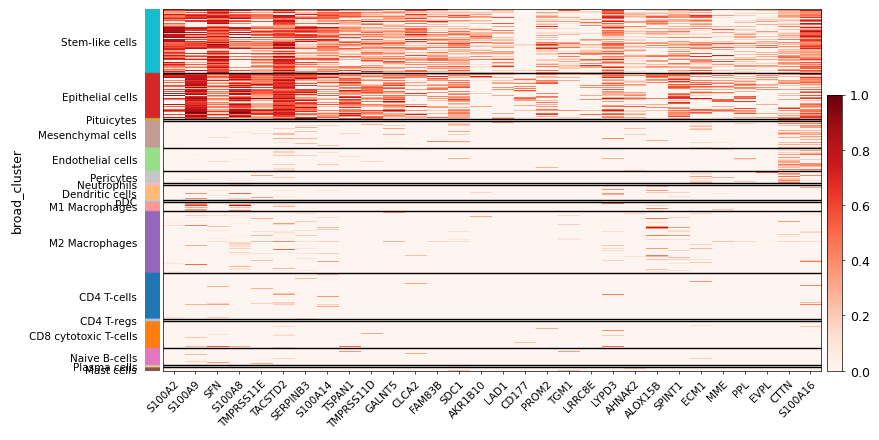

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
markers = markers_df_intersection["genes"][:30]
# --- 1. enforce category order (assumed already done, but safe to repeat) ---
adata_pcp.obs["broad_cluster"] = (
    adata_pcp.obs["broad_cluster"]
    .astype("category")
    .cat.reorder_categories(cell_type_order, ordered=True)
)

# --- 2. build colors_dict from your palette mapping ---
color_idx = {
    "Stem-like cells": 18,
    "Macrophages": 7,
    "Epithelial cells": 6,
    "T-cells": 0,
    "Mast cells": 10,
    "Endothelial cells": 5,
    "Pericytes": 15,
    "Mesenchymal cells": 11,
    "Dendritic cells": 3,
    "B-cells": 12,
    "Neutrophils": 13,
    "CD8 cytotoxic T-cells": 2,
    "CD4 T-cells": 0,
    "Naive B-cells": 12,
    "M2 Macrophages": 8,
    "M1 Macrophages": 7,
    "CD4 T-regs": 1,
    "pDC": 19,
    "Plasma cells": 17,
    "Pituicytes": 16,
}
import seaborn as sns

palette = sns.color_palette("tab20")   # len == 20, indices 0–19
colors_dict = {k: palette[v] for k, v in color_idx.items()}

# --- 3. push colors into adata in the SAME order as the categories ---
# scanpy reads colors from adata.uns[f"{groupby}_colors"], positionally
adata_pcp.uns["broad_cluster_colors"] = [
    colors_dict[c] for c in adata_pcp.obs["broad_cluster"].cat.categories
]

gene_order = [g for g in markers if g in adata_pcp.var_names]

# --- 5. Nature rcParams ---
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 2,
    'ytick.major.size': 2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

n_groups = adata_pcp.obs["broad_cluster"].nunique()
n_genes = len(gene_order)

sc.pl.heatmap(
    adata_pcp,
    var_names=gene_order,
    groupby='broad_cluster',
    swap_axes=False,
    cmap='Reds',
    standard_scale='var',
    dendrogram=False,
    show_gene_labels=True,
    figsize=( max(3.0, 0.3 * n_genes), max(3.2, 0.28 * n_groups)),

    show=False,
)

fig = plt.gcf()
for ax in fig.axes:
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.tick_params(length=2, width=0.5)

main_ax = fig.axes[0]
plt.setp(main_ax.get_xticklabels(), rotation=45, ha='right',
         rotation_mode='anchor')

# save at 600 dpi, both raster and vector
fig.savefig('/content/drive/MyDrive/human_pcp/intersection_heatmap_30.png', dpi=600,
            bbox_inches='tight', facecolor='white')
fig.savefig('/content/drive/MyDrive/human_pcp/intersection_heatmap_30.svg',
            bbox_inches='tight', facecolor='white')

plt.show()

# Repeat for TF markers

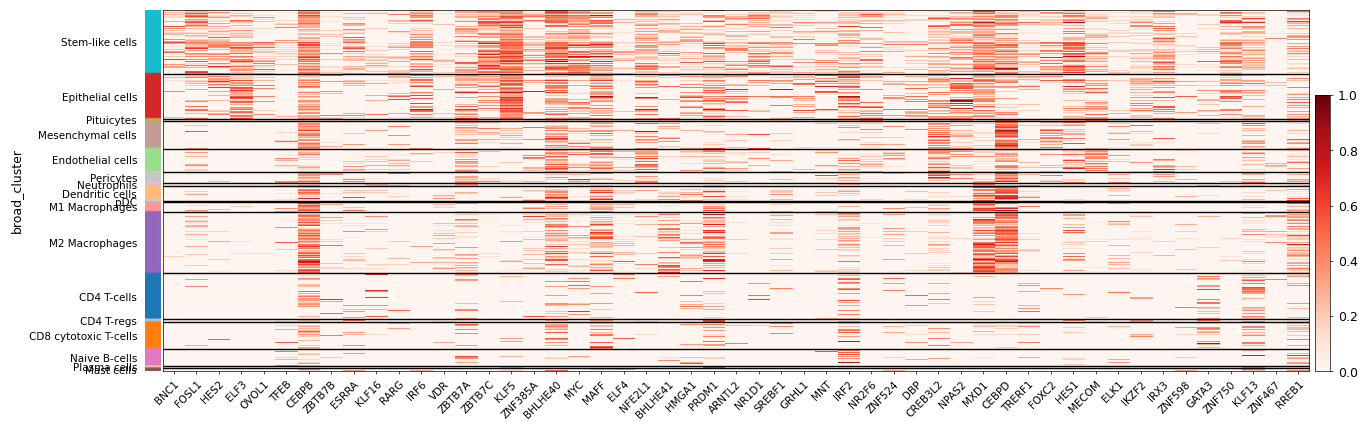

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
markers = rna_seq_results_tfs["gene_symbol"].values
# --- 1. enforce category order (assumed already done, but safe to repeat) ---
adata_pcp.obs["broad_cluster"] = (
    adata_pcp.obs["broad_cluster"]
    .astype("category")
    .cat.reorder_categories(cell_type_order, ordered=True)
)

# --- 2. build colors_dict from your palette mapping ---
color_idx = {
    "Stem-like cells": 18,
    "Macrophages": 7,
    "Epithelial cells": 6,
    "T-cells": 0,
    "Mast cells": 10,
    "Endothelial cells": 5,
    "Pericytes": 15,
    "Mesenchymal cells": 11,
    "Dendritic cells": 3,
    "B-cells": 12,
    "Neutrophils": 13,
    "CD8 cytotoxic T-cells": 2,
    "CD4 T-cells": 0,
    "Naive B-cells": 12,
    "M2 Macrophages": 8,
    "M1 Macrophages": 7,
    "CD4 T-regs": 1,
    "pDC": 19,
    "Plasma cells": 17,
    "Pituicytes": 16,
}
import seaborn as sns

palette = sns.color_palette("tab20")   # len == 20, indices 0–19
colors_dict = {k: palette[v] for k, v in color_idx.items()}

# --- 3. push colors into adata in the SAME order as the categories ---
# scanpy reads colors from adata.uns[f"{groupby}_colors"], positionally
adata_pcp.uns["broad_cluster_colors"] = [
    colors_dict[c] for c in adata_pcp.obs["broad_cluster"].cat.categories
]

gene_order = [g for g in markers if g in adata_pcp.var_names]

# --- 5. Nature rcParams ---
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 2,
    'ytick.major.size': 2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

n_groups = adata_pcp.obs["broad_cluster"].nunique()
n_genes = len(gene_order)

sc.pl.heatmap(
    adata_pcp,
    var_names=gene_order,
    groupby='broad_cluster',
    swap_axes=False,
    cmap='Reds',
    standard_scale='var',
    dendrogram=False,
    show_gene_labels=True,
    figsize=( max(3.0, 0.3 * n_genes), max(3.2, 0.28 * n_groups)),

    show=False,
)

fig = plt.gcf()
for ax in fig.axes:
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.tick_params(length=2, width=0.5)

main_ax = fig.axes[0]
plt.setp(main_ax.get_xticklabels(), rotation=45, ha='right',
         rotation_mode='anchor')

# save at 600 dpi, both raster and vector
fig.savefig('/content/drive/MyDrive/human_pcp/intersection_heatmap_TF.png', dpi=600,
            bbox_inches='tight', facecolor='white')
fig.savefig('/content/drive/MyDrive/human_pcp/intersection_heatmap_TF.svg',
            bbox_inches='tight', facecolor='white')

plt.show()

In [ ]:
to_plot = markers_df_all[markers_df_all["genes"].isin(gene_order)]
#sort by logFC
to_plot = to_plot.sort_values(by="logFC", ascending=False)
to_plot.head(5)

,genes,logFC
2746,ELF3,6.577073
4232,HES2,6.351828
11075,ZNF750,5.918530
6655,OVOL1,5.707342
4665,IRF6,5.649836


In [ ]:
gene_order = [g for g in to_plot["genes"] if g in adata_pcp.var_names]
gene_order

['ELF3',
 'HES2',
 'ZNF750',
 'OVOL1',
 'IRF6',
 'KLF5',
 'BNC1',
 'IRX3',
 'ZBTB7C',
 'FOXC2',
 'NPAS2',
 'MECOM',
 'GRHL1',
 'HES1',
 'ARNTL2',
 'NR2F6',
 'BHLHE41',
 'NR1D1',
 'ZNF385A',
 'RARG',
 'FOSL1',
 'MYC',
 'IKZF2',
 'DBP',
 'HMGA1',
 'BHLHE40',
 'MXD1',
 'NFE2L1',
 'MAFF',
 'PRDM1',
 'VDR',
 'ZBTB7B',
 'CREB3L2',
 'SREBF1',
 'CEBPB',
 'ESRRA',
 'TRERF1',
 'ZNF467',
 'GATA3',
 'KLF16',
 'ZNF524',
 'ZNF598',
 'MNT',
 'ZBTB7A',
 'ELK1',
 'CEBPD',
 'IRF2',
 'KLF13',
 'RREB1',
 'ELF4',
 'TFEB']

In [ ]:
adata_pcp.obs["broad_cluster"]

AAACCCACAACTCATG-0              Neutrophils
AAACCCACACATGAAA-0    CD8 cytotoxic T-cells
AAACGAACACGCTGAC-0              CD4 T-cells
AAACGAAGTACGGTTT-0          Stem-like cells
AAACGAAGTTGGCCGT-0              CD4 T-cells
                              ...          
TTTGTTGGTCCTATAG-9         Epithelial cells
TTTGTTGGTGGTCTGC-9          Stem-like cells
TTTGTTGGTTCGAACT-9        Endothelial cells
TTTGTTGGTTGCTGAT-9         Epithelial cells
TTTGTTGTCTATCACT-9         Epithelial cells
Name: broad_cluster, Length: 66577, dtype: category
Categories (17, str): ['Stem-like cells' < 'Epithelial cells' < 'Pituicytes' < 'Mesenchymal cells' < ... <
                       'CD8 cytotoxic T-cells' < 'Naive B-cells' < 'Plasma cells' < 'Mast cells']

In [ ]:
import numpy as np

adata_pcp.obs["stem_epi_other"] = np.where(
    adata_pcp.obs["broad_cluster"].isin(["Epithelial cells", "Stem-like cells"]),
    adata_pcp.obs["broad_cluster"].astype(str),
    "Other"
)


In [ ]:
cell_type_order = [
    "Stem-like cells",
    "Epithelial cells",
    "Other",
]

# make sure it's categorical, then enforce order
adata_pcp.obs["stem_epi_other"] = (
    adata_pcp.obs["stem_epi_other"]
    .astype("category")
    .cat.reorder_categories(cell_type_order, ordered=True)
)

# sanity check
print(adata_pcp.obs["stem_epi_other"].cat.categories.tolist())

['Stem-like cells', 'Epithelial cells', 'Other']


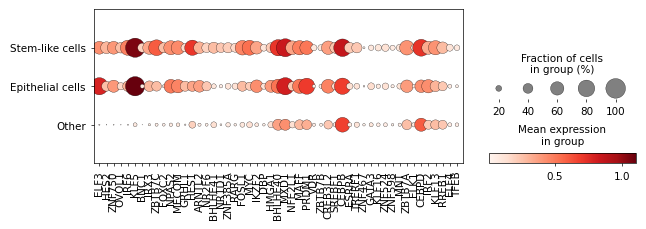

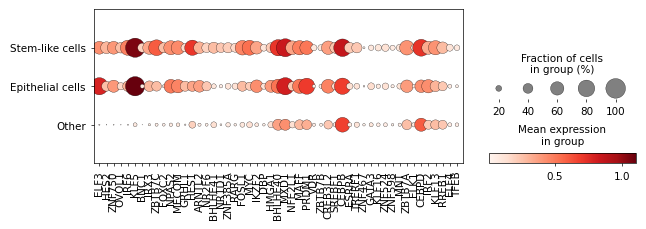

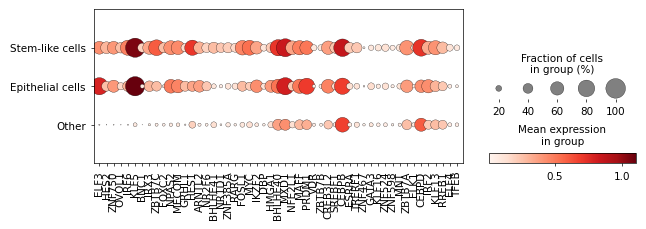

In [ ]:
#
dp = sc.pl.dotplot(
    adata_pcp,
    gene_order,
    groupby="stem_epi_other",
    log=True,
    swap_axes=False,
    figsize=(7,2),
    return_fig=True,      # <-- this returns the DotPlot object
)
dp.make_figure()         # builds the figure

dp.savefig("dotplot1.png", dpi=800, bbox_inches="tight")
dp.savefig("dotplot1.svg", bbox_inches="tight")